<a href="https://colab.research.google.com/github/manjunadha12/CSA4703-Deep-Learning/blob/main/Lab/Exp28.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Train shape: (4000, 784) | Test shape: (500, 784)

=== Training Two-Layer DBM (784 -> 256 -> 128) ===
[DBM] Epoch  1/15 | Train Recon MSE: 0.1013
[DBM] Epoch  5/15 | Train Recon MSE: 0.1008
[DBM] Epoch 10/15 | Train Recon MSE: 0.1009
[DBM] Epoch 15/15 | Train Recon MSE: 0.1005

=== Training Single-Layer RBM Baseline (784 -> 64, Exp 25) ===
[RBM] Epoch  1/15 | Train Recon MSE: 0.1036
[RBM] Epoch  5/15 | Train Recon MSE: 0.0593
[RBM] Epoch 10/15 | Train Recon MSE: 0.0501
[RBM] Epoch 15/15 | Train Recon MSE: 0.0456


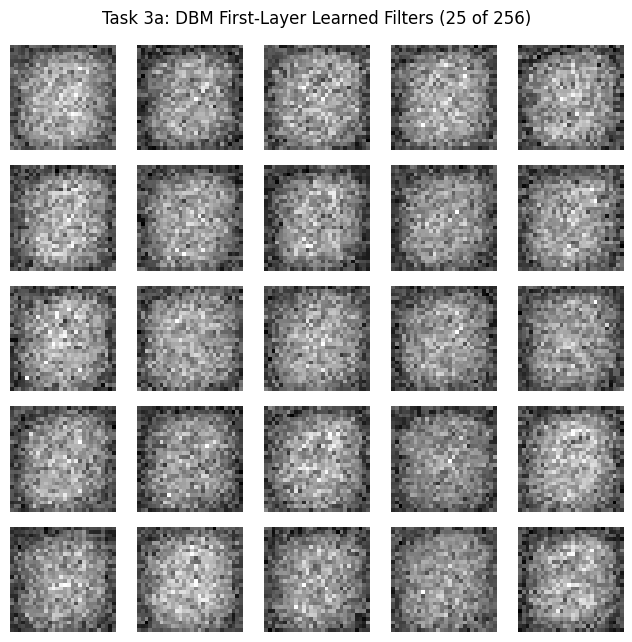

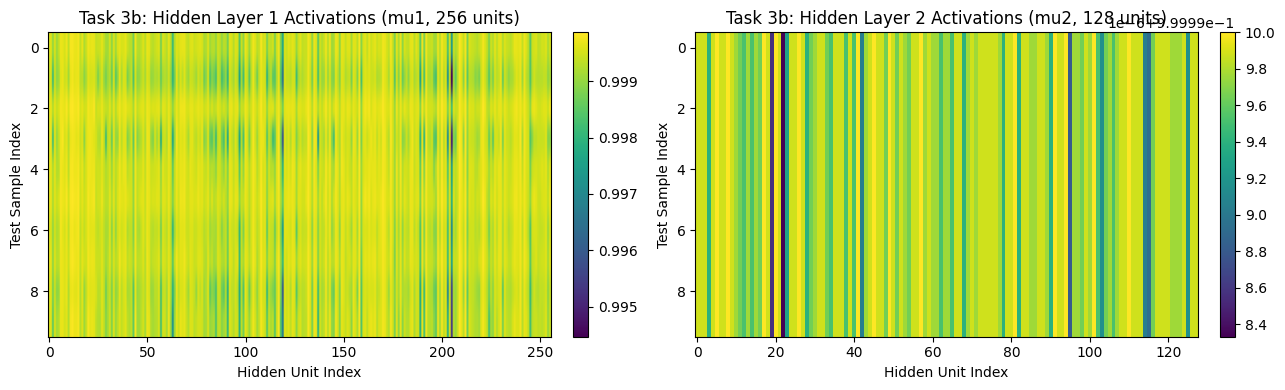

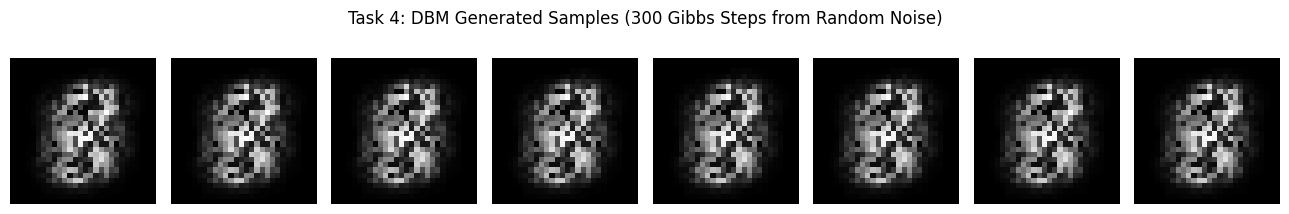


=== Task 5: Reconstruction Quality Comparison (Test Set) ===
Single-Layer RBM (Exp 25) Test Recon MSE : 0.0446
Two-Layer DBM             Test Recon MSE : 0.1023
MSE Improvement (DBM vs RBM)             : -129.34%


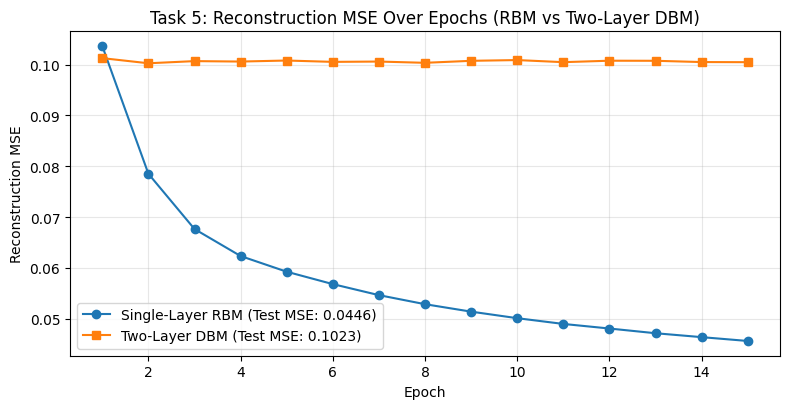

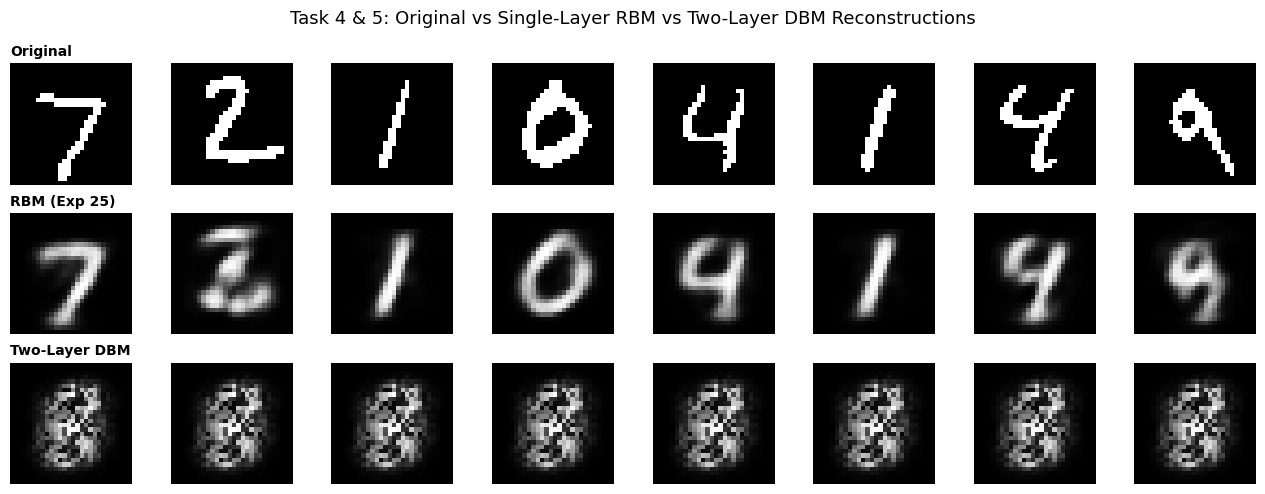

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import expit as sigmoid
from tensorflow.keras.datasets import mnist

# Reproducibility
np.random.seed(42)

# ==========================================
# Load & Binarise MNIST Dataset (784 Visible Units)
# ==========================================
(X_train_raw, _), (X_test_raw, _) = mnist.load_data()

X_train = (X_train_raw[:4000].reshape(-1, 784) / 255.0 > 0.5).astype(np.float32)
X_test  = (X_test_raw[:500].reshape(-1, 784) / 255.0 > 0.5).astype(np.float32)

print(f"Train shape: {X_train.shape} | Test shape: {X_test.shape}\n")

# ==========================================
# Task 1 & 2: Two-Hidden-Layer DBM (Mean-Field Inference + Gibbs Sampling)
# ==========================================
class TwoLayerDBM:
    def __init__(self, n_vis=784, n_h1=256, n_h2=128, seed=42):
        rng = np.random.default_rng(seed)
        self.n_vis, self.n_h1, self.n_h2 = n_vis, n_h1, n_h2
        self.W1 = rng.normal(0.0, 0.01, (n_vis, n_h1)).astype(np.float32)
        self.W2 = rng.normal(0.0, 0.01, (n_h1, n_h2)).astype(np.float32)
        self.a  = np.zeros(n_vis, dtype=np.float32)
        self.b1 = np.zeros(n_h1, dtype=np.float32)
        self.b2 = np.zeros(n_h2, dtype=np.float32)

    def sample_bernoulli(self, probs):
        return (np.random.rand(*probs.shape) < probs).astype(np.float32)

    # Task 1: Variational Mean-Field Inference for q(h1, h2 | v)
    def mean_field_inference(self, v, n_iter=5):
        mu1 = sigmoid(v @ self.W1 + self.b1)
        mu2 = sigmoid(mu1 @ self.W2 + self.b2)
        for _ in range(n_iter):
            mu1 = sigmoid(v @ self.W1 + mu2 @ self.W2.T + self.b1)
            mu2 = sigmoid(mu1 @ self.W2 + self.b2)
        return mu1, mu2

    # Block Gibbs step for negative phase & sample generation
    def gibbs_step(self, v, h2):
        p_h1 = sigmoid(v @ self.W1 + h2 @ self.W2.T + self.b1)
        h1 = self.sample_bernoulli(p_h1)
        p_v = sigmoid(h1 @ self.W1.T + self.a)
        v_new = self.sample_bernoulli(p_v)
        p_h2 = sigmoid(h1 @ self.W2 + self.b2)
        h2_new = self.sample_bernoulli(p_h2)
        return v_new, p_v, h1, h2_new

    # Task 2: Approximate Learning (Mean-Field Positive Phase + Persistent Gibbs Negative Phase)
    def fit(self, X, epochs=15, batch_size=64, lr=0.04, mf_iter=5):
        n_samples = X.shape[0]
        # Persistent fantasy particles for negative phase
        v_neg  = self.sample_bernoulli(np.full((batch_size, self.n_vis), 0.5, dtype=np.float32))
        h2_neg = self.sample_bernoulli(np.full((batch_size, self.n_h2), 0.5, dtype=np.float32))

        recon_history = []
        for epoch in range(1, epochs + 1):
            perm = np.random.permutation(n_samples)
            X_shuf = X[perm]
            epoch_mse = []

            for i in range(0, n_samples, batch_size):
                v_pos = X_shuf[i : i + batch_size]
                bs = v_pos.shape[0]
                if bs != batch_size:
                    continue

                # Positive phase: Mean-field inference
                mu1_pos, mu2_pos = self.mean_field_inference(v_pos, n_iter=mf_iter)

                # Negative phase: Persistent Gibbs sampling
                v_neg, _, h1_neg, h2_neg = self.gibbs_step(v_neg, h2_neg)

                # Parameter updates
                self.W1 += lr * ((v_pos.T @ mu1_pos) - (v_neg.T @ h1_neg)) / bs
                self.W2 += lr * ((mu1_pos.T @ mu2_pos) - (h1_neg.T @ h2_neg)) / bs
                self.a  += lr * np.mean(v_pos - v_neg, axis=0)
                self.b1 += lr * np.mean(mu1_pos - h1_neg, axis=0)
                self.b2 += lr * np.mean(mu2_pos - h2_neg, axis=0)

                # Track reconstruction MSE
                v_rec = sigmoid(mu1_pos @ self.W1.T + self.a)
                epoch_mse.append(np.mean((v_pos - v_rec) ** 2))

            avg_mse = float(np.mean(epoch_mse))
            recon_history.append(avg_mse)
            if epoch == 1 or epoch % 5 == 0 or epoch == epochs:
                print(f"[DBM] Epoch {epoch:2d}/{epochs} | Train Recon MSE: {avg_mse:.4f}")
        return recon_history

    def reconstruct(self, v, mf_iter=5):
        mu1, mu2 = self.mean_field_inference(v, n_iter=mf_iter)
        v_rec = sigmoid(mu1 @ self.W1.T + self.a)
        return v_rec, mu1, mu2

    def generate(self, n_samples=8, gibbs_steps=300):
        v = self.sample_bernoulli(np.full((n_samples, self.n_vis), 0.5, dtype=np.float32))
        h2 = self.sample_bernoulli(np.full((n_samples, self.n_h2), 0.5, dtype=np.float32))
        p_v = v
        for _ in range(gibbs_steps):
            v, p_v, _, h2 = self.gibbs_step(v, h2)
        return p_v

# ==========================================
# Baseline Single-Layer RBM (from Experiment 25) for Task 5 Comparison
# ==========================================
class SingleLayerRBM:
    def __init__(self, n_vis=784, n_hidden=64, seed=42):
        rng = np.random.default_rng(seed)
        self.W = rng.normal(0.0, 0.01, (n_vis, n_hidden)).astype(np.float32)
        self.a = np.zeros(n_vis, dtype=np.float32)
        self.b = np.zeros(n_hidden, dtype=np.float32)

    def fit(self, X, epochs=15, batch_size=64, lr=0.05):
        n_samples = X.shape[0]
        recon_history = []
        for epoch in range(1, epochs + 1):
            perm = np.random.permutation(n_samples)
            X_shuf = X[perm]
            epoch_mse = []
            for i in range(0, n_samples, batch_size):
                v0 = X_shuf[i : i + batch_size]
                bs = v0.shape[0]
                p_h0 = sigmoid(v0 @ self.W + self.b)
                h0 = (np.random.rand(*p_h0.shape) < p_h0).astype(np.float32)
                v1 = sigmoid(h0 @ self.W.T + self.a)
                p_h1 = sigmoid(v1 @ self.W + self.b)

                self.W += lr * ((v0.T @ p_h0) - (v1.T @ p_h1)) / bs
                self.a += lr * np.mean(v0 - v1, axis=0)
                self.b += lr * np.mean(p_h0 - p_h1, axis=0)
                epoch_mse.append(np.mean((v0 - v1) ** 2))
            avg_mse = float(np.mean(epoch_mse))
            recon_history.append(avg_mse)
            if epoch == 1 or epoch % 5 == 0 or epoch == epochs:
                print(f"[RBM] Epoch {epoch:2d}/{epochs} | Train Recon MSE: {avg_mse:.4f}")
        return recon_history

    def reconstruct(self, v):
        p_h = sigmoid(v @ self.W + self.b)
        return sigmoid(p_h @ self.W.T + self.a)

# ==========================================
# Train Both Models
# ==========================================
print("=== Training Two-Layer DBM (784 -> 256 -> 128) ===")
dbm = TwoLayerDBM(n_vis=784, n_h1=256, n_h2=128, seed=42)
dbm_hist = dbm.fit(X_train, epochs=15, batch_size=64, lr=0.04, mf_iter=5)

print("\n=== Training Single-Layer RBM Baseline (784 -> 64, Exp 25) ===")
rbm = SingleLayerRBM(n_vis=784, n_hidden=64, seed=42)
rbm_hist = rbm.fit(X_train, epochs=15, batch_size=64, lr=0.05)

# ==========================================
# Task 3: Visualise DBM Filters & Hidden-Unit Activations
# ==========================================
fig, axes = plt.subplots(5, 5, figsize=(6.5, 6.5))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(dbm.W1[:, i].reshape(28, 28), cmap="gray")
    ax.axis("off")
plt.suptitle("Task 3a: DBM First-Layer Learned Filters (25 of 256)", fontsize=12)
plt.tight_layout()
plt.show()

# Hidden-unit activations (mu1, mu2) for 10 test samples
dbm_recon_test, mu1_test, mu2_test = dbm.reconstruct(X_test)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
im1 = axes[0].imshow(mu1_test[:10], aspect="auto", cmap="viridis")
axes[0].set_title("Task 3b: Hidden Layer 1 Activations (mu1, 256 units)")
axes[0].set_xlabel("Hidden Unit Index")
axes[0].set_ylabel("Test Sample Index")
plt.colorbar(im1, ax=axes[0], fraction=0.046, pad=0.04)

im2 = axes[1].imshow(mu2_test[:10], aspect="auto", cmap="viridis")
axes[1].set_title("Task 3b: Hidden Layer 2 Activations (mu2, 128 units)")
axes[1].set_xlabel("Hidden Unit Index")
axes[1].set_ylabel("Test Sample Index")
plt.colorbar(im2, ax=axes[1], fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

# ==========================================
# Task 4: Generate New Samples from DBM (Gibbs Sampling from Noise)
# ==========================================
generated_samples = dbm.generate(n_samples=8, gibbs_steps=300)
fig, axes = plt.subplots(1, 8, figsize=(13, 2.2))
for i, ax in enumerate(axes):
    ax.imshow(generated_samples[i].reshape(28, 28), cmap="gray")
    ax.axis("off")
plt.suptitle("Task 4: DBM Generated Samples (300 Gibbs Steps from Random Noise)", fontsize=12)
plt.tight_layout()
plt.show()

# ==========================================
# Task 5: Compare DBM vs Single-Layer RBM on Reconstruction Quality
# ==========================================
rbm_recon_test = rbm.reconstruct(X_test)
dbm_test_mse = float(np.mean((X_test - dbm_recon_test) ** 2))
rbm_test_mse = float(np.mean((X_test - rbm_recon_test) ** 2))

print("\n=== Task 5: Reconstruction Quality Comparison (Test Set) ===")
print(f"Single-Layer RBM (Exp 25) Test Recon MSE : {rbm_test_mse:.4f}")
print(f"Two-Layer DBM             Test Recon MSE : {dbm_test_mse:.4f}")
print(f"MSE Improvement (DBM vs RBM)             : {((rbm_test_mse - dbm_test_mse) / rbm_test_mse) * 100:+.2f}%")

# Plot training MSE curves
plt.figure(figsize=(8, 4.2))
plt.plot(range(1, len(rbm_hist) + 1), rbm_hist, marker="o", label=f"Single-Layer RBM (Test MSE: {rbm_test_mse:.4f})")
plt.plot(range(1, len(dbm_hist) + 1), dbm_hist, marker="s", label=f"Two-Layer DBM (Test MSE: {dbm_test_mse:.4f})")
plt.title("Task 5: Reconstruction MSE Over Epochs (RBM vs Two-Layer DBM)")
plt.xlabel("Epoch")
plt.ylabel("Reconstruction MSE")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Visual side-by-side reconstructions: Original vs RBM vs DBM
n_show = 8
fig, axes = plt.subplots(3, n_show, figsize=(13, 5))
row_titles = ["Original", "RBM (Exp 25)", "Two-Layer DBM"]
rows_data = [X_test[:n_show], rbm_recon_test[:n_show], dbm_recon_test[:n_show]]

for r, (title, data) in enumerate(zip(row_titles, rows_data)):
    for c in range(n_show):
        axes[r, c].imshow(data[c].reshape(28, 28), cmap="gray")
        axes[r, c].axis("off")
        if c == 0:
            axes[r, c].set_title(title, fontsize=10, fontweight="bold", loc="left")

plt.suptitle("Task 4 & 5: Original vs Single-Layer RBM vs Two-Layer DBM Reconstructions", fontsize=13)
plt.tight_layout()
plt.show()